# MC2 · Augmentation · Day 1 – Data & Domain
**Country:** Japan · **Topic:** Night-time festival photography (Akita Kanto Festival)

*Scope of this day: define use case, problem, image, structure of interest and objective. No augmentation methods are introduced or applied.*

## 1. Use case
The **Akita Kanto Festival** (Akita City, Japan, 3–6 August) is a night festival in which performers balance tall bamboo poles (*kanto*) carrying up to 46 paper lanterns (*chōchin*) each. The lanterns carry lettering (neighbourhood association names, sponsor names such as "ALSOK") and a red crest.

Heritage archives, the tourism board and visitor apps would like to **automatically recognise which lantern towers and lantern markings appear in visitor night photos**, e.g. for cataloguing, searching photos by team or sponsor, and counting lanterns per tower.

## 2. Problem statement
- **Scarce, uniform data:** the festival takes place on only four evenings a year, so labelled images are rare and mostly show the same few viewpoints and the same night lighting.
- **Difficult imaging conditions:**
  - extreme dynamic range: self-illuminated lanterns against an almost black sky;
  - low light forces high ISO, which causes sensor noise, most visible in dark regions;
  - glow/blooming around bright lanterns reduces the contrast of thin lettering;
  - swaying poles and moving performers cause motion blur in handheld or long exposures;
  - mixed warm lantern light and neon/shop lighting create colour casts.
- **Domain shift:** a model trained on a few photos will not generalise to other cameras, exposure settings, weather (humidity, haze) or capture time (dusk vs. late night).

Augmentation is therefore needed to simulate realistic variation in capture conditions and increase the variability of the data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMG_PATH = "akita-kanto-festival-by-annintofu-flickr-2187739691.jpg"
img = np.array(Image.open(IMG_PATH).convert("RGB"))
H, W, C = img.shape
print(f"shape: {img.shape}, dtype: {img.dtype}, range: [{img.min()}, {img.max()}]")

shape: (1366, 2048, 3), dtype: uint8, range: [0, 255]


## 3. Selected image
**Origin:** photograph "Akita Kanto Festival" by *annintofu*, Flickr (file `akita-kanto-festival-by-annintofu-flickr-2187739691.jpg`).
Found via Bunnik Tours photo gallery (https://www.bunniktours.com.au/tools/photo-gallery/asia-incl-india-and-sri-lanka/colours-of-northern-japan-kanto-and-nebuta-festivals-2026), credited there as "Akita Kanto Festival in Akita, Japan by Annintofu/Flickr". No licence is stated on that page and the original Flickr page could not be located; the image is used here for non-commercial coursework only, with attribution.

**Content:** night scene, wide-angle shot from a low viewpoint looking up. Two large lantern towers dominate the foreground (left: black "ALSOK" lettering; right: red Akita crest, association-name lanterns at the top). Two more towers are tilted in perspective on the right. Performers in happi coats stand in the foreground, some carrying small lanterns. Shop and convenience-store signs are visible in the background; the sky is black.

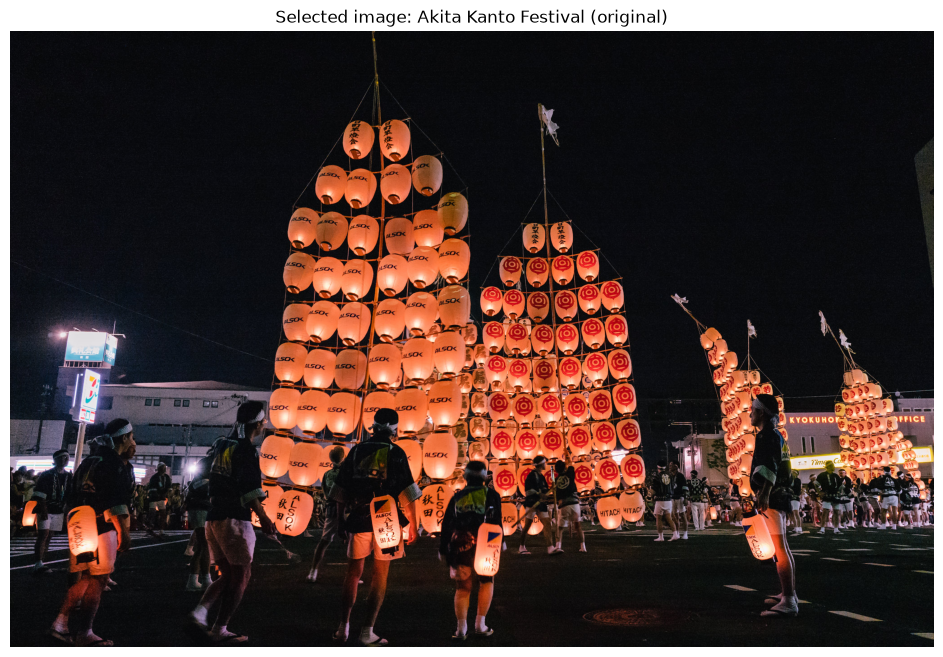

In [2]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img)
ax.set_title("Selected image: Akita Kanto Festival (original)")
ax.axis("off")
plt.show()

**Plot explanation – original image.** Full-resolution view of the selected photo (2048×1366 px, RGB). It shows the setting the whole challenge is based on: bright, self-lit lantern towers against a nearly black sky, with dark foreground silhouettes. Even at this scale, noise in the dark regions and the glow around the lanterns are visible.

### Relevant visual structures
- **Regular grid** of bright, nearly identical ellipses (lantern rows and columns) with thin dark horizontal bamboo crossbars.
- **Thin dark lettering** (kanji and Latin) on bright paper: edge-defined, high-frequency content.
- **Red circular crest** on orange paper: colour and shape contrast.
- **Smooth glowing gradients** inside each lantern with a brighter rim around the opening.
- **Large uniform dark areas** (sky) where noise is most visible.
- **Sharp silhouettes** of performers in the foreground.

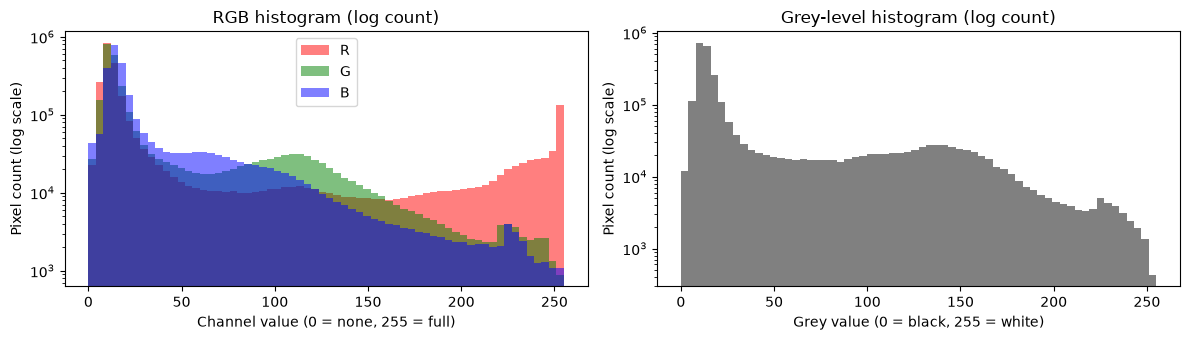

share of pixels with mean intensity < 30: 69.8%
share of pixels with mean intensity > 225: 0.7%


In [3]:
gray = img.mean(axis=2)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for i, (c, name) in enumerate(zip("rgb", ["R", "G", "B"])):
    axs[0].hist(img[..., i].ravel(), bins=64, color=c, alpha=0.5, label=name)
axs[0].set_yscale("log"); axs[0].set_title("RGB histogram (log count)"); axs[0].legend()
axs[1].hist(gray.ravel(), bins=64, color="gray"); axs[1].set_yscale("log")
axs[1].set_title("Grey-level histogram (log count)")
axs[0].set_xlabel("Channel value (0 = none, 255 = full)")
axs[1].set_xlabel("Grey value (0 = black, 255 = white)")
for a in axs: a.set_ylabel("Pixel count (log scale)")
plt.tight_layout(); plt.show()
print(f"share of pixels with mean intensity < 30: {(gray < 30).mean():.1%}")
print(f"share of pixels with mean intensity > 225: {(gray > 225).mean():.1%}")

**Plot explanation – histograms (log-scaled counts).** Left: histogram per colour channel; right: grey-level histogram (mean of R, G, B). The y-axis is logarithmic, so the small bright regions remain visible next to the huge dark mass.
- A very tall peak at low values (about 10–20) is the black sky and shadows (≈70 % of pixels below 30).
- A broad second mode around 120–160 is the lantern paper; it is not a narrow peak but spreads across the mid-tones.
- The red channel (left plot) piles up at 255: the warm lantern light clips in R, which flattens detail and lets the glow bleed. Green and blue stay lower, which explains the orange colour cast.
- Together this is a very wide dynamic range with a strong dark peak and clipping in one channel: the exposure situation that makes lettering fragile.

## 4. Structure of interest
**Chosen structure:** the black **"ALSOK" lettering on the lanterns of the left tower.**

**Why:** it is thin, high-frequency, edge-defined content on a bright, glowing background, so it is the first thing lost under capture degradation. It is also a clearly bounded structure that can be reused in later days (edges, segmentation).

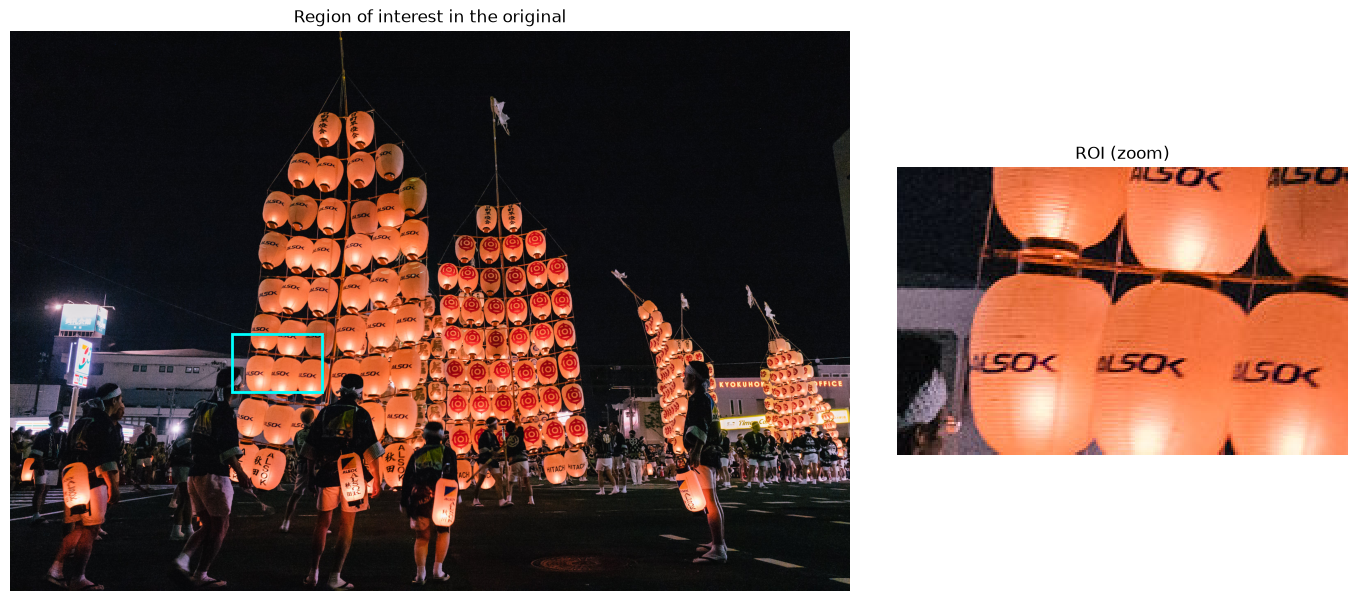

In [4]:
# Region of interest: approximate crop around one "ALSOK" lantern in the left tower.
# Coordinates refer to the 2048x1366 original; adjust after viewing the figure below.
x0, x1 = 540, 760
y0, y1 = 740, 880

fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2, 1]})
axs[0].imshow(img)
axs[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=2))
axs[0].set_title("Region of interest in the original"); axs[0].axis("off")
axs[1].imshow(img[y0:y1, x0:x1], interpolation="nearest")
axs[1].set_title("ROI (zoom)"); axs[1].axis("off")
plt.tight_layout(); plt.show()

**Plot explanation – region of interest.** Left: the original with the ROI (cyan rectangle, x 540–760, y 740–880) on the lower part of the left tower. Right: the same ROI enlarged with nearest-neighbour interpolation, so individual pixels are visible. It contains three lanterns with the black "ALSOK" lettering. Visible in the zoom: strokes only a few pixels wide, a slightly noisy and blocky texture (JPEG compression and sensor noise), and a bright glow near the lantern centres. This is the structure the augmentation objective refers to.

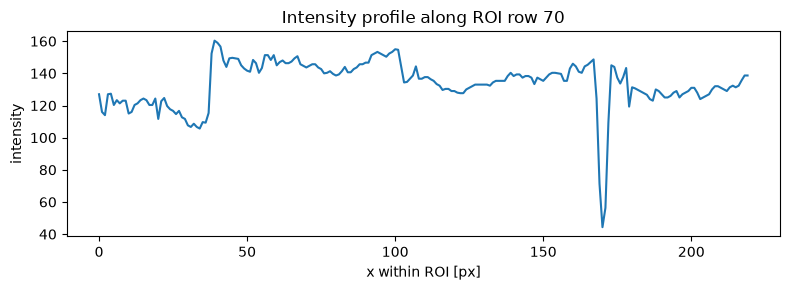

ROI mean: 121.6, min: 0.0, max: 243.3


In [5]:
# Intensity profile across the lettering (one horizontal line through the ROI).
# This only describes the image; no processing is applied.
roi = img[y0:y1, x0:x1].mean(axis=2)
row = roi.shape[0] // 2
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(roi[row]); ax.set_xlabel("x within ROI [px]"); ax.set_ylabel("intensity")
ax.set_title(f"Intensity profile along ROI row {row}")
plt.tight_layout(); plt.show()
print(f"ROI mean: {roi.mean():.1f}, min: {roi.min():.1f}, max: {roi.max():.1f}")

**Plot explanation – intensity profile.** Mean intensity along one horizontal row through the ROI (row 70, x = 0–220 px). Most of the row lies at about 120–160, which is the glowing paper. Two features stand out:
- A step at x ≈ 38 (≈ 107 → 160): the boundary between two lanterns / a lantern and its surroundings.
- A narrow dip down to ≈ 45 at x ≈ 170, only about 5–10 px wide: a stroke of the lettering. Its contrast against the paper is roughly 90–100 grey levels.

The lettering is therefore a thin, high-contrast feature on a bright background. Noise, blur or a change in exposure would change the width and depth of this dip first, which is why it is a good indicator for the later days. The small fluctuations of ±5–10 levels along the paper are existing noise and texture.

### How the challenge manifests in this structure
- **Contrast depends on exposure:** when the paper saturates, glow bleeds into the strokes and thins or removes them.
- **Noise and slight motion blur** disturb stroke edges that are only a few pixels wide.
- **Perspective** from the low camera angle distorts letter shapes towards the top of the tower.
- **Near-identical neighbours:** all lanterns look alike, so small degradations in the lettering are what separate one team or sponsor from another.

Because there are only a few such photos, the lettering appears under very few capture conditions in the data.

## 5. Objective of augmentation
Increase the variability of the training images by **simulating realistic night-capture degradations** (different sensor noise levels, exposure and contrast of the glowing lanterns, softness of the lettering), so that a recognition model **remains robust on thin lettering and crest edges under capture conditions not covered by the few original photos**.

Augmented images must remain plausible as real festival photos and must not change the *identity* of the content (the text must still read as the same text). Degradation that makes the structure unrecognisable defeats the purpose.

---
# Day 2 · Methodological Design
*Scope: method selection, parameter reasoning and experimental design only. No augmentation is applied to the photo and no metric is used. The plots are theory curves computed from formulas, not results.*

**Inputs from Day 1** (read by eye from the ROI profile, rough values): stroke width ≈ 6 px, stroke depth ≈ 95 grey levels, noise already present ≈ 5 levels.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

STROKE_WIDTH_PX = 6    # approx. width of one "ALSOK" stroke [px]
STROKE_DEPTH    = 95   # approx. grey-level difference paper vs. stroke
EXISTING_NOISE  = 5    # approx. noise already present on the paper [levels]

## 1. Strategy
Two photometric (non-geometric) augmentations that imitate a **night photo**, applied in the order of a real camera: **blur → noise → clip to 0–255** (optics first, sensor noise afterwards, 8-bit limit last).

| | A. Gaussian blur | B. Additive Gaussian noise |
|---|---|---|
| Principle | Convolution with a Gaussian kernel, i.e. a weighted neighbourhood average. In the frequency domain it multiplies the spectrum by $H(f)=e^{-2\pi^2\sigma^2f^2}$, a **low-pass filter**. | $I' = \operatorname{clip}(I+N)$ with $N\sim\mathcal N(0,\sigma^2)$, independent per pixel and channel (**white noise**: all frequencies). |
| Models | motion blur, soft optics, glow | high-ISO sensor noise (shot + read noise, amplified at night) |
| Why for the "ALSOK" strokes | The strokes are thin (high frequency) and are attenuated first: contrast and edge steepness drop. | A few grey levels of jitter is large relative to a 6-px stroke, so edges become ragged; the paper becomes grainy. |
| Parameter | $\sigma_{\text{blur}}$ [px] (kernel size derived: $k=2\lceil3\sigma\rceil+1$) | $\sigma_{\text{noise}}$ [grey levels] (channels independent, fixed seed) |
| Expected effect | larger σ → softer image, wider and shallower strokes | larger σ → more grain, lower stroke-to-noise ratio |

**Why together:** blur *removes* high frequencies, noise *adds* them, so they attack the stroke from opposite sides, like a shaky, high-ISO shot. **Order:** noise is created at the sensor *after* the optics, so it must not be blurred (noise → blur would give unrealistically smooth, cloudy noise).
**Simplifications:** the Gaussian blur is isotropic (real motion blur is directional) and the noise has a constant σ (real shot noise grows with brightness).
**Not selected:** gamma/exposure (possible extension), colour jitter and JPEG artefacts (little relevance for black lettering on bright paper).

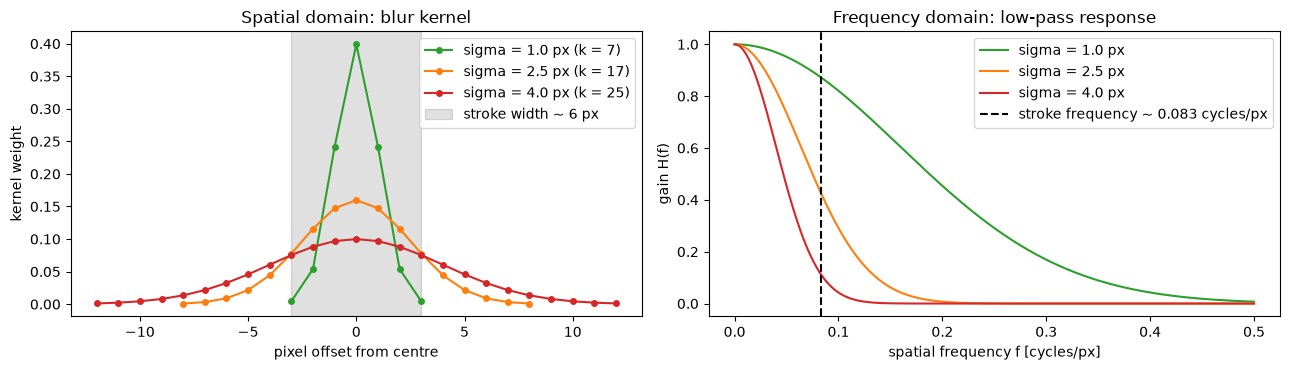

In [7]:
def gaussian_kernel_1d(sigma):
    k = 2 * int(np.ceil(3 * sigma)) + 1
    x = np.arange(k) - k // 2
    g = np.exp(-x**2 / (2 * sigma**2))
    return x, g / g.sum()

sigmas, colors = [1.0, 2.5, 4.0], ["tab:green", "tab:orange", "tab:red"]
f = np.linspace(0, 0.5, 400)                 # cycles per pixel, 0.5 = Nyquist limit
f_stroke = 1 / (2 * STROKE_WIDTH_PX)         # rough stroke frequency

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for s, c in zip(sigmas, colors):
    x, g = gaussian_kernel_1d(s)
    axs[0].plot(x, g, "o-", color=c, ms=4, label=f"sigma = {s} px (k = {len(x)})")
    axs[1].plot(f, np.exp(-2 * np.pi**2 * s**2 * f**2), color=c, label=f"sigma = {s} px")
axs[0].axvspan(-STROKE_WIDTH_PX / 2, STROKE_WIDTH_PX / 2, color="black", alpha=0.12, label="stroke width ~ 6 px")
axs[0].set_xlabel("pixel offset from centre"); axs[0].set_ylabel("kernel weight"); axs[0].set_title("Spatial domain: blur kernel"); axs[0].legend()
axs[1].axvline(f_stroke, color="black", ls="--", label=f"stroke frequency ~ {f_stroke:.3f} cycles/px")
axs[1].set_xlabel("spatial frequency f [cycles/px]"); axs[1].set_ylabel("gain H(f)"); axs[1].set_title("Frequency domain: low-pass response"); axs[1].legend()
plt.tight_layout(); plt.show()

**Plot explanation – blur in two domains.** Left: the weights of the averaging window. A narrow curve (σ = 1) stays close to the original pixel; a wide one (σ = 4) mixes many pixels. The grey band is the stroke width: with σ = 2.5 the kernel is about as wide as a stroke, so the dark pixels are averaged with bright paper. Right: the same operation as a filter. The gain is 1 at f = 0 (average brightness is kept) and falls with frequency, faster for larger σ. At the stroke frequency (dashed) about **87 %** (σ = 1), **43 %** (σ = 2.5) and **11 %** (σ = 4) of the stroke contrast remain. Both panels show one operation (convolution theorem: convolution in space = multiplication in frequency). For an ideal 6-px bar, σ = 2.5 keeps ≈ 77 % of its depth (design estimate, not a metric).

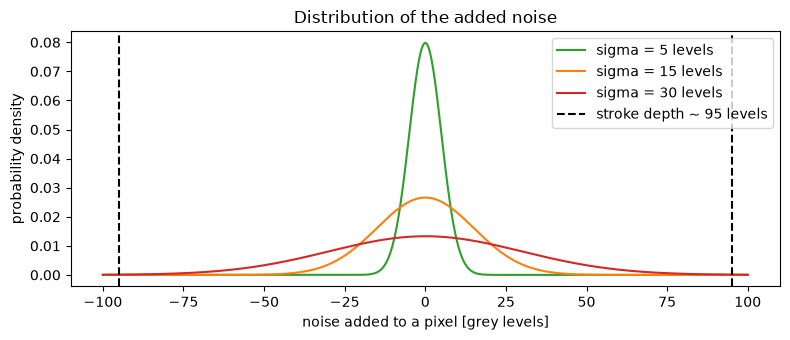

In [8]:
x = np.linspace(-100, 100, 801)
pdf = lambda x, s: np.exp(-x**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(8, 3.5))
for s, c in zip([EXISTING_NOISE, 15, 30], colors):
    ax.plot(x, pdf(x, s), color=c, label=f"sigma = {s} levels")
ax.axvline(-STROKE_DEPTH, color="black", ls="--"); ax.axvline(STROKE_DEPTH, color="black", ls="--", label=f"stroke depth ~ {STROKE_DEPTH} levels")
ax.set_xlabel("noise added to a pixel [grey levels]"); ax.set_ylabel("probability density"); ax.set_title("Distribution of the added noise"); ax.legend()
plt.tight_layout(); plt.show()

**Plot explanation – noise distribution.** Each bell shows how likely a given change of a pixel value is (negative = darker, positive = brighter). The curve is centred on 0, so the average brightness stays; its width is σ. σ = 5 is the noise already in the photo. With σ = 15, 99.7 % of pixels change by less than 45 levels (3σ), clearly below the stroke depth (dashed, ≈ 95): the strokes stay readable, but edges are ragged. With σ = 30 the 3σ range reaches the stroke depth and strokes become barely separable. Stroke-to-noise ratio $20\log_{10}(95/\sigma)$: 25.6 dB (σ = 5), **16.0 dB (σ = 15)**, 10.0 dB (σ = 30). Independent noises add in variance: $\sqrt{5^2+15^2}\approx15.8$ levels total.

## 2. Configurations
One factor changes at a time, so each effect can be attributed to one cause.

| ID | $\sigma_{\text{blur}}$ [px] | $\sigma_{\text{noise}}$ [levels] | Purpose |
|---|---|---|---|
| **C0** baseline | 0 | 0 | reference (original photo) |
| **C1** noise only | 0 | 15 | isolate sensor noise |
| **C2** blur only | 2.5 | 0 | isolate softness |
| **C3** blur + noise | 2.5 | 15 | combined night shot; shows whether effects add up |

**Values:** σ_blur = 2.5 px is about the stroke width (visible effect, strokes still present); σ_noise = 15 is ≈ 3× the existing noise (≈ 16 dB, strokes readable). Both are moderate on purpose, because augmentation must keep the text intact.

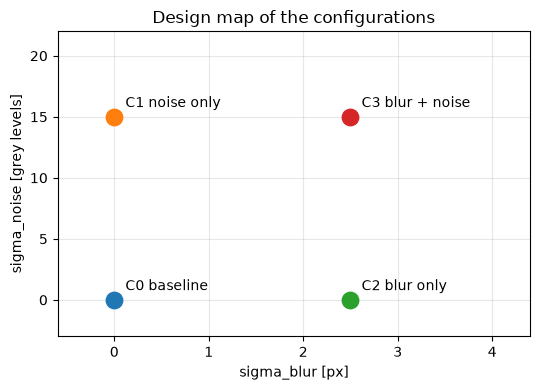

In [9]:
SEED = 42
CONFIGS = {
    "C0 baseline":     dict(blur_sigma=0.0, noise_sigma=0.0),
    "C1 noise only":   dict(blur_sigma=0.0, noise_sigma=15.0),
    "C2 blur only":    dict(blur_sigma=2.5, noise_sigma=0.0),
    "C3 blur + noise": dict(blur_sigma=2.5, noise_sigma=15.0),
}  # specification only, applied on Day 3; order: blur -> noise -> clip

fig, ax = plt.subplots(figsize=(5.5, 4))
for name, p in CONFIGS.items():
    ax.scatter(p["blur_sigma"], p["noise_sigma"], s=140, zorder=3)
    ax.annotate(name, (p["blur_sigma"], p["noise_sigma"]), textcoords="offset points", xytext=(8, 7))
ax.set_xlim(-0.6, 4.4); ax.set_ylim(-3, 22); ax.grid(alpha=0.3)
ax.set_xlabel("sigma_blur [px]"); ax.set_ylabel("sigma_noise [grey levels]"); ax.set_title("Design map of the configurations")
plt.tight_layout(); plt.show()

**Plot explanation – design map.** Each point is one configuration; blur strength runs to the right, noise strength upward. C0 at the origin is "no augmentation". C1 and C2 each differ from C0 in exactly one coordinate (controlled comparison), and C3 combines both. Four runs in a 2×2 layout give the most information without loosely connected variants.

**Expected effects (hypotheses, checked on Days 3–5):** C1 grainy, ragged stroke edges · C2 soft, strokes wider and shallower · C3 soft and grainy, lowest legibility (noise stays sharp because it is added after the blur).

---
# Day 3 · Technical Implementation
*Scope: implement the two augmentations from Day 2, verify them on a simple test image, apply the four predefined configurations to the photo, and show intermediate and final outputs. **No quantitative evaluation and no interpretation** (Days 4 and 5). Captions only describe what is shown and how to read it.*

**Plan of this day**
1. Parameters (taken unchanged from Day 2) and the exact processing sequence
2. Implementation of blur, noise and the combined pipeline
3. Verification on a simple test image
4. Application to the photo: intermediate steps, final results of all configurations, zoom on the ROI

## 1. Parameters and processing sequence
The configurations are the ones fixed on Day 2 (`CONFIGS`, `SEED`). Nothing is tuned on this day. The sequence for every configuration is

| step | operation | parameter | skipped when |
|---|---|---|---|
| 0 | convert the 8-bit image to float32 | – | never |
| 1 | Gaussian blur (separable convolution, reflect padding) | $\sigma_{\text{blur}}$ [px], kernel size $k=2\lceil3\sigma\rceil+1$ | $\sigma_{\text{blur}}=0$ |
| 2 | generate a noise layer $N\sim\mathcal N(0,\sigma_{\text{noise}}^2)$, independent per pixel and channel | $\sigma_{\text{noise}}$ [levels], `SEED` | $\sigma_{\text{noise}}=0$ |
| 3 | add the noise layer to the blurred image | – | – |
| 4 | round and clip to 0–255, convert back to `uint8` | – | never |

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# CONFIGS and SEED come from Day 2 (re-stated here only to print the parameter trace)
print(f"SEED = {SEED} | order: blur -> noise -> add -> round & clip -> uint8\n")
print(f"{'configuration':<18}{'sigma_blur [px]':>16}{'kernel size k':>15}{'sigma_noise [levels]':>22}")
for name, p in CONFIGS.items():
    k = 2 * int(np.ceil(3 * p["blur_sigma"])) + 1 if p["blur_sigma"] > 0 else "-"
    print(f"{name:<18}{p['blur_sigma']:>16}{k:>15}{p['noise_sigma']:>22}")

SEED = 42 | order: blur -> noise -> add -> round & clip -> uint8

configuration      sigma_blur [px]  kernel size k  sigma_noise [levels]
C0 baseline                    0.0              -                   0.0
C1 noise only                  0.0              -                  15.0
C2 blur only                   2.5             17                   0.0
C3 blur + noise                2.5             17                  15.0


## 2. Implementation
### Core knowledge used in the code
- **Separable convolution.** A 2-D Gaussian equals a 1-D Gaussian applied along the rows and then along the columns. For kernel size $k$ this needs $2k$ instead of $k^2$ multiplications per pixel (17 instead of 289 for $\sigma=2.5$).
- **Boundary handling.** Near the image border the window leaves the image. We pad by **reflection** (mirror the pixels at the border), which avoids dark or bright edges that zero-padding would create.
- **Float arithmetic.** Computations run in `float32`. In `uint8` a value such as 250 + 10 would wrap around to 4 instead of saturating at 255.
- **Reproducible noise.** `numpy.random.default_rng(seed)` creates a generator; the same seed gives exactly the same noise layer. C1 and C3 therefore use **the identical noise layer**, so they differ only by the blur.
- **Round, then clip.** Rounding to integers and clipping to [0, 255] happens once at the end.

The blur is implemented **by hand** with NumPy so every step is visible; a library function is used afterwards only as an independent cross-check (section 3).

In [11]:
def gaussian_kernel_1d(sigma):
    # Sampled and normalised 1-D Gaussian; size k = 2*ceil(3*sigma)+1 (covers +-3 sigma).
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1)
    g = np.exp(-x**2 / (2.0 * sigma**2))
    return (g / g.sum()).astype(np.float32)

def convolve_axis(a, kernel, axis):
    # 1-D convolution of an (H, W, C) array along one axis with reflect padding.
    r = len(kernel) // 2
    pad = [(0, 0)] * a.ndim
    pad[axis] = (r, r)
    p = np.pad(a, pad, mode="reflect")
    n = a.shape[axis]
    out = np.zeros_like(a)
    for i, w in enumerate(kernel):                    # sum of shifted, weighted copies
        out += w * np.take(p, np.arange(i, i + n), axis=axis)
    return out

def gaussian_blur(a, sigma):
    # Separable Gaussian blur: rows, then columns. sigma = 0 returns an unchanged copy.
    if sigma == 0:
        return a.copy()
    k = gaussian_kernel_1d(sigma)
    return convolve_axis(convolve_axis(a, k, axis=0), k, axis=1)

def noise_layer(shape, sigma, seed):
    # Zero-mean Gaussian noise, independent per pixel and channel. sigma = 0 returns zeros.
    if sigma == 0:
        return np.zeros(shape, dtype=np.float32)
    rng = np.random.default_rng(seed)
    return rng.normal(0.0, sigma, size=shape).astype(np.float32)

def augment(img_u8, blur_sigma, noise_sigma, seed, keep_steps=False):
    # Full pipeline: blur -> noise -> add -> round & clip. Optionally returns the intermediate arrays.
    x0 = img_u8.astype(np.float32)                    # step 0
    xb = gaussian_blur(x0, blur_sigma)                # step 1
    nz = noise_layer(x0.shape, noise_sigma, seed)     # step 2
    xs = xb + nz                                      # step 3 (not yet clipped, may leave 0..255)
    out = np.clip(np.rint(xs), 0, 255).astype(np.uint8)   # step 4
    steps = dict(input=x0, blurred=xb, noise=nz, summed=xs) if keep_steps else None
    return out, steps

## 3. Verification on a simple test image
Before touching the photo, the functions are checked on inputs whose correct result is known.

**Test image:** 96 × 160 px, uniform grey background (200) with three vertical dark bars (value 60) of width 4, 6 and 8 px, i.e. an idealised version of the lettering strokes (≈ 6 px). A separate single-pixel impulse image is used to read off the blur kernel.

**Checks** (these test the *code*, not the augmentation quality):
1. kernel sums to 1 and is symmetric,
2. impulse response equals the analytic 2-D Gaussian,
3. blur matches an independent library implementation (`scipy.ndimage.gaussian_filter`, same σ, mirror boundary, truncation at 3σ),
4. blur preserves the mean brightness,
5. noise layer has mean ≈ 0 and standard deviation ≈ σ,
6. same seed gives the same noise,
7. all-zero parameters return the input unchanged,
8. output is `uint8` within 0–255.

In [12]:
from scipy.ndimage import gaussian_filter

# --- simple test image: grey background, three dark vertical bars (widths 4, 6, 8 px)
test = np.full((96, 160, 3), 200, np.uint8)
for xs_, w in [(24, 4), (70, 6), (116, 8)]:
    test[:, xs_:xs_ + w] = 60

# --- impulse image: one bright pixel in the centre
imp = np.zeros((41, 41, 3), np.float32); imp[20, 20] = 255

S_B, S_N = 2.5, 15.0
checks = []

k = gaussian_kernel_1d(S_B)
checks.append(("1 kernel sums to 1 and is symmetric", abs(k.sum() - 1) < 1e-6 and np.allclose(k, k[::-1])))

resp = gaussian_blur(imp, S_B)[..., 0]
analytic = 255 * np.outer(k, k)
r = len(k) // 2
diff = np.abs(resp[20 - r:20 + r + 1, 20 - r:20 + r + 1] - analytic).max()
checks.append((f"2 impulse response = analytic Gaussian (max diff {diff:.2e})", diff < 1e-3))

mine = gaussian_blur(test.astype(np.float32), S_B)
lib = np.stack([gaussian_filter(test[..., c].astype(np.float32), S_B, mode="mirror", truncate=3.0) for c in range(3)], axis=-1)
diff = np.abs(mine - lib).max()
checks.append((f"3 matches scipy gaussian_filter (max diff {diff:.2e} levels)", diff < 1e-2))

d_mean = abs(mine.mean() - test.mean())
checks.append((f"4 mean brightness preserved (|change| = {d_mean:.3f} levels)", d_mean < 0.5))

big = noise_layer((1000, 1000, 3), S_N, SEED)
checks.append((f"5 noise mean {big.mean():+.3f} (target 0), std {big.std():.3f} (target {S_N})", abs(big.mean()) < 0.05 and abs(big.std() - S_N) < 0.1))

checks.append(("6 same seed -> identical noise", np.array_equal(noise_layer((50, 50, 3), S_N, SEED), noise_layer((50, 50, 3), S_N, SEED))))

ident, _ = augment(test, 0.0, 0.0, SEED)
checks.append(("7 sigma_blur = sigma_noise = 0 returns the input", np.array_equal(ident, test)))

o, _ = augment(test, S_B, S_N, SEED)
checks.append(("8 output is uint8 within 0..255", o.dtype == np.uint8 and o.min() >= 0 and o.max() <= 255))

for text, ok in checks:
    print(("PASS  " if ok else "FAIL  ") + text)
assert all(ok for _, ok in checks), "a verification check failed"

PASS  1 kernel sums to 1 and is symmetric
PASS  2 impulse response = analytic Gaussian (max diff 4.77e-07)
PASS  3 matches scipy gaussian_filter (max diff 3.05e-05 levels)
PASS  4 mean brightness preserved (|change| = 0.000 levels)
PASS  5 noise mean +0.010 (target 0), std 14.997 (target 15.0)
PASS  6 same seed -> identical noise
PASS  7 sigma_blur = sigma_noise = 0 returns the input
PASS  8 output is uint8 within 0..255


**Verification output – how to read it.** Each line is one check; `PASS` means the implementation behaves as the theory in Day 2 states. Check 3 is the independent confirmation: a library implementation, written by someone else, gives the same pixels (up to float rounding). Checks 5 and 6 confirm that the noise has the intended statistics and is reproducible.

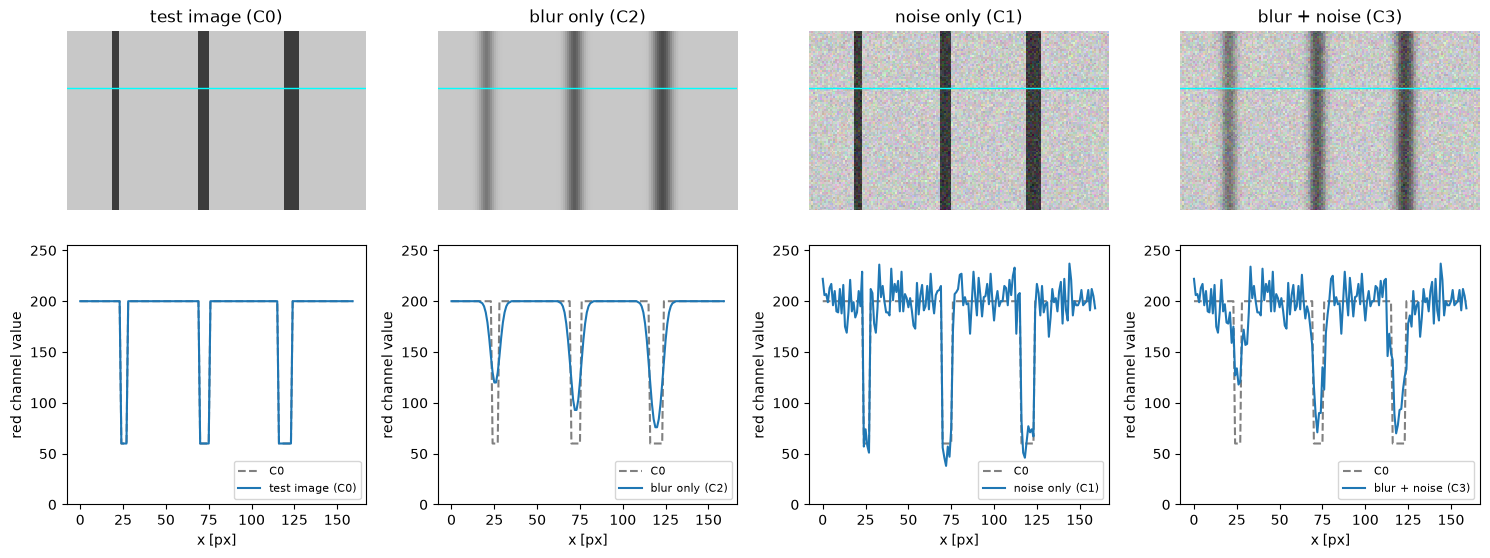

In [13]:
variants = {
    "test image (C0)":      augment(test, 0.0, 0.0, SEED)[0],
    "blur only (C2)":       augment(test, S_B, 0.0, SEED)[0],
    "noise only (C1)":      augment(test, 0.0, S_N, SEED)[0],
    "blur + noise (C3)":    augment(test, S_B, S_N, SEED)[0],
}
row = 30  # image row used for the profile plot

fig, axs = plt.subplots(2, 4, figsize=(15, 6), gridspec_kw={"height_ratios": [1.1, 1]})
for j, (name, im) in enumerate(variants.items()):
    axs[0, j].imshow(im, interpolation="nearest"); axs[0, j].axhline(row, color="cyan", lw=1)
    axs[0, j].set_title(name); axs[0, j].axis("off")
    axs[1, j].plot(variants["test image (C0)"][row, :, 0], color="gray", ls="--", label="C0")
    axs[1, j].plot(im[row, :, 0], color="tab:blue", label=name)
    axs[1, j].set_ylim(0, 255); axs[1, j].set_xlabel("x [px]"); axs[1, j].set_ylabel("red channel value"); axs[1, j].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Plot explanation – test image.**
- **Top row:** the test image and the three augmented versions (the cyan line marks the row used below). Bars of width 4, 6 and 8 px stand for the lettering strokes.
- **Bottom row:** the red-channel values along that row (blue) against the unchanged test image (grey dashed). A sharp rectangular dip is a bar; its depth is how dark the stroke is.
- **How to read it:** in *blur only*, the blue curve is the grey one with rounded edges and the same average level. In *noise only*, the rectangular shape is kept but the line becomes jagged. In *blur + noise*, the rounded shape carries the jaggedness. The three bar widths let us see the width dependence of the blur, which Day 2 predicted (thin bars are affected most).
- **Purpose:** it demonstrates that the functions do what the design says on an input where the correct answer is known. Interpretation for the real photo follows on Days 4–5.

## 4. Application to the selected photo
All four configurations are applied with the functions above. The ROI is the "ALSOK" region from Day 1 (`x0, x1, y0, y1`). Results are also written to `outputs/day3/` as PNG files so every image can be traced to its file name.

In [14]:
os.makedirs("outputs/day3", exist_ok=True)
results, steps_c3 = {}, None
for name, p in CONFIGS.items():
    keep = name.startswith("C3")
    out, st = augment(img, p["blur_sigma"], p["noise_sigma"], SEED, keep_steps=keep)
    results[name] = out
    if keep: steps_c3 = st
    fname = "outputs/day3/" + name.split()[0] + ".png"
    Image.fromarray(out).save(fname)
    print(f"{name:<18} sigma_blur={p['blur_sigma']:<4} sigma_noise={p['noise_sigma']:<5} -> {fname}   shape={out.shape}, dtype={out.dtype}")
assert np.array_equal(results["C0 baseline"], img), "baseline must equal the original"

C0 baseline        sigma_blur=0.0  sigma_noise=0.0   -> outputs/day3/C0.png   shape=(1366, 2048, 3), dtype=uint8


C1 noise only      sigma_blur=0.0  sigma_noise=15.0  -> outputs/day3/C1.png   shape=(1366, 2048, 3), dtype=uint8


C2 blur only       sigma_blur=2.5  sigma_noise=0.0   -> outputs/day3/C2.png   shape=(1366, 2048, 3), dtype=uint8


C3 blur + noise    sigma_blur=2.5  sigma_noise=15.0  -> outputs/day3/C3.png   shape=(1366, 2048, 3), dtype=uint8


### 4.1 Intermediate steps of the combined configuration (C3), ROI
The sequence of C3 is shown step by step so that the transformation can be followed.

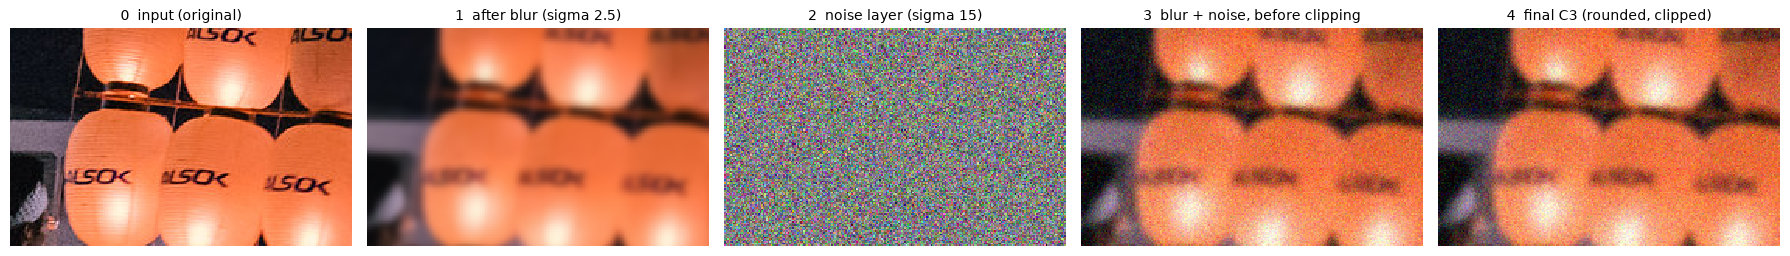

value range of the summed image before clipping: -65.7 to 324.2


In [15]:
st = steps_c3
roi = (slice(y0, y1), slice(x0, x1))
nz = st["noise"][roi]
panels = [
    ("0  input (original)",              np.clip(st["input"][roi], 0, 255).astype(np.uint8)),
    ("1  after blur (sigma 2.5)",        np.clip(st["blurred"][roi], 0, 255).astype(np.uint8)),
    ("2  noise layer (sigma 15)",        np.clip(nz / (6 * CONFIGS['C3 blur + noise']['noise_sigma']) + 0.5, 0, 1)),
    ("3  blur + noise, before clipping", np.clip(st["summed"][roi], 0, 255).astype(np.uint8)),
    ("4  final C3 (rounded, clipped)",   results["C3 blur + noise"][roi]),
]
fig, axs = plt.subplots(1, 5, figsize=(18, 3.6))
for a, (t, im) in zip(axs, panels):
    a.imshow(im, interpolation="nearest", vmin=0 if im.dtype != np.uint8 else None, vmax=1 if im.dtype != np.uint8 else None)
    a.set_title(t, fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()
print("value range of the summed image before clipping:", round(float(st['summed'].min()), 1), "to", round(float(st['summed'].max()), 1))

**Plot explanation – intermediate steps (ROI of C3).**
- **Panel 0:** the unchanged ROI (three "ALSOK" lanterns).
- **Panel 1:** the same ROI after step 1 only. Sharp details are replaced by neighbourhood averages.
- **Panel 2:** the noise layer on its own, drawn in colour because it is generated independently for R, G and B. Mid-grey means 0; the display range is ±3σ = ±45 levels, so brighter/darker speckles are positive/negative changes. It has no relation to the picture content, because it is random.
- **Panel 3:** panel 1 plus panel 2 before rounding and clipping. The printed range shows that the sum can leave 0–255; this is why step 4 exists.
- **Panel 4:** the final image after rounding and clipping, i.e. what is saved as `outputs/day3/C3.png`.
- **How to read it:** left to right follows the code order (blur, then noise, then sum); each panel is the direct input of the next step.

### 4.2 Final results of all configurations (full image)

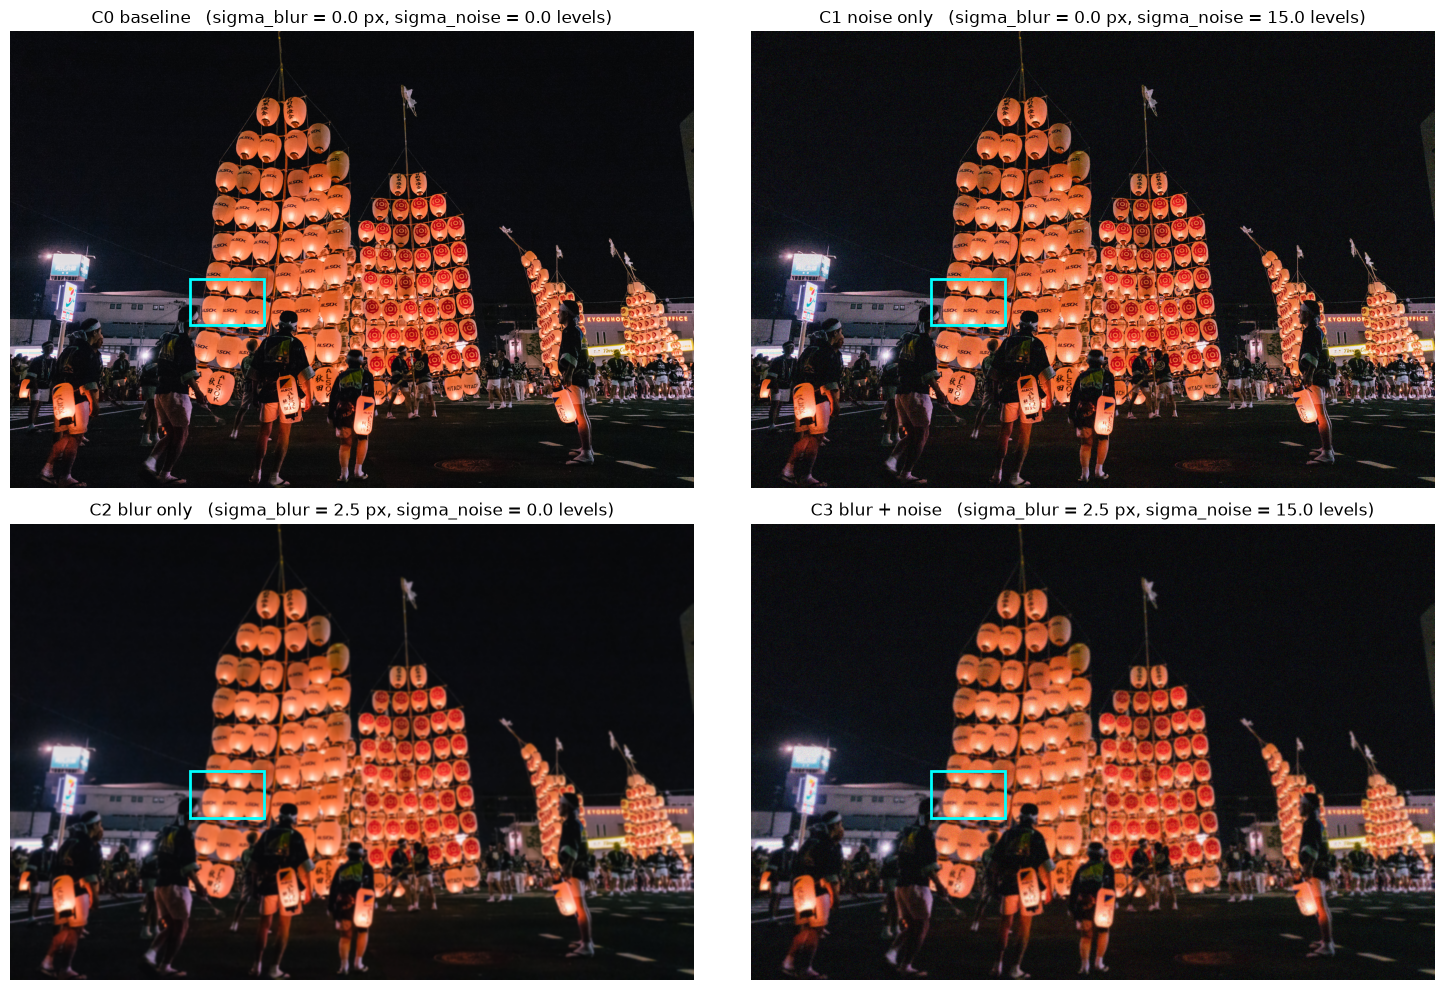

In [16]:
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
for a, (name, im) in zip(axs.ravel(), results.items()):
    p = CONFIGS[name]
    a.imshow(im); a.axis("off")
    a.set_title(f"{name}   (sigma_blur = {p['blur_sigma']} px, sigma_noise = {p['noise_sigma']} levels)")
    a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=2))
plt.tight_layout(); plt.show()

**Plot explanation – all configurations.** The 2 × 2 grid follows the design map of Day 2: top left is the baseline C0, top right C1 (noise only), bottom left C2 (blur only), bottom right C3 (both). All panels use the same display size and the same value range, so they can be compared directly. The cyan rectangle is the ROI of Day 1, enlarged in the next figure. The parameters in each title are exactly the values stored in `CONFIGS`.

### 4.3 Zoom on the region of interest

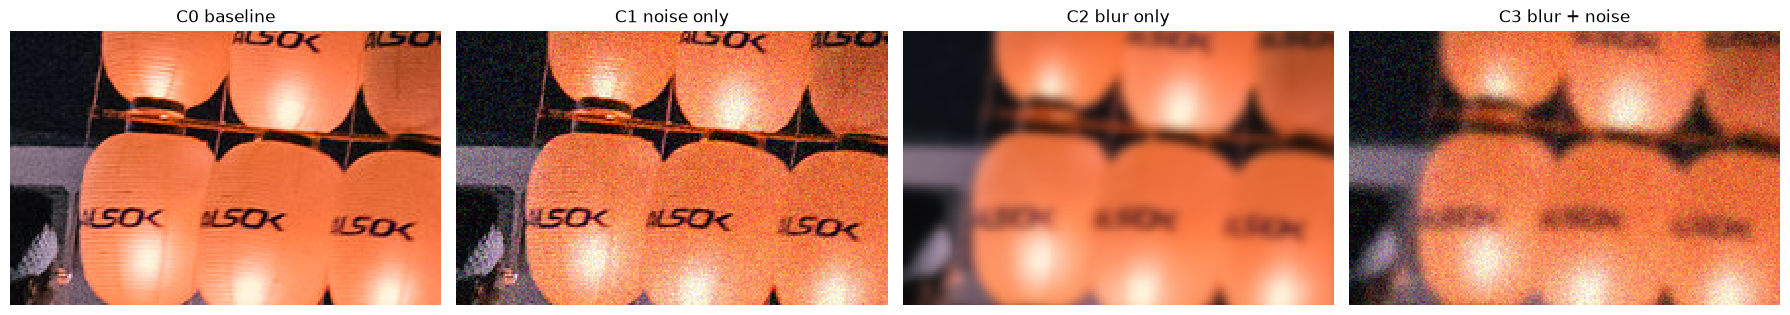

In [17]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for a, (name, im) in zip(axs, results.items()):
    a.imshow(im[roi], interpolation="nearest"); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.show()

**Plot explanation – ROI zoom.** The same ROI (x 540–760, y 740–880) cut out of each of the four results and shown with nearest-neighbour interpolation, so individual pixels are visible and nothing is smoothed by the display. The order is C0, C1, C2, C3. This is the structure the augmentation was designed for (the "ALSOK" lettering). What the differences mean is deliberately not discussed here; the measurement follows on Day 4 and the interpretation on Day 5.